# Residual Analysis and Probabilistic Forecasting

<small><em>Author: Alexandre MATHIEU, Postdoctoral Researcher / DTU Wind</em></small>

This notebook introduces how to evaluate forecast errors and represent forecast uncertainty. It first analyses forecast residual patterns and then compares different probabilistic forecasting approaches.

#### Notebook workflow

The notebook is organized into four parts:

0. **Data loading and exploration**: Load power and weather forecasts data.
1. **Residual analysis: first part**: Compute forecast errors and assess deterministic forecast performance.
2. **Residual analysis: second part**: Explore further residual distributions.
3. **Probabilistic forecasts**: Compare a Gaussian residual model with Gradient Boosting Quantile Regression.

The students are expected to answer the instructions in <span style="color:red"> red </span>. They are invited to modify and create/execute some new notebook cells to explore data and try out new methods.

**Execute the notebook cells in order** so that the results from the preceding steps are computed and can be used further.

#### Data sources

- The bidding zone-level (DK2) power data forecasts and actuals are originally fetched from ENTSOE: https://transparency.entsoe.eu 
- The weather data forecasts are originally fetched from some IFS archive dataset



## 0. Load data

Just execute the cells below to load python packages. If needed for your answers, add new packages here.

In [309]:
# Import python packages

# Data wrangling packages
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns 

# Statistic models and tests
from scipy.stats import shapiro, norm
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox

Load:

- Actual PV power production.
- Its associated day-ahead point forecasts.
- The weather forecasts at Risø, DENMARK. (Global Horizontal Irradiance)

All values correspond to hourly "average" starting at the time of the timestamp.
Times are in UTC.

In [310]:
# Import some data from a csv file into the jupyter notebook
df = pd.read_csv("fcact_data.csv", index_col=0)
df.index = pd.to_datetime(df.index) # convert "index" to "DatetimeIndex" for manipulation purpose

# Show the first 15 lines
df.head(15)

,power_act_mw,power_fc_mw,ghi_fc_w.m2
2018-01-01 00:00:00+00:00,0.00,0.0,0.000000
2018-01-01 01:00:00+00:00,0.00,0.0,0.000000
2018-01-01 02:00:00+00:00,0.00,0.0,0.000000
2018-01-01 03:00:00+00:00,0.00,0.0,0.000000
2018-01-01 04:00:00+00:00,0.00,0.0,0.000000
2018-01-01 05:00:00+00:00,0.00,0.0,0.000000
2018-01-01 06:00:00+00:00,0.00,0.0,0.000000
2018-01-01 07:00:00+00:00,0.63,0.0,0.330537
2018-01-01 08:00:00+00:00,4.24,5.0,9.585571
2018-01-01 09:00:00+00:00,13.09,7.0,20.493290


Visualize PV Power forecasts versus actuals, along with weather forecasts

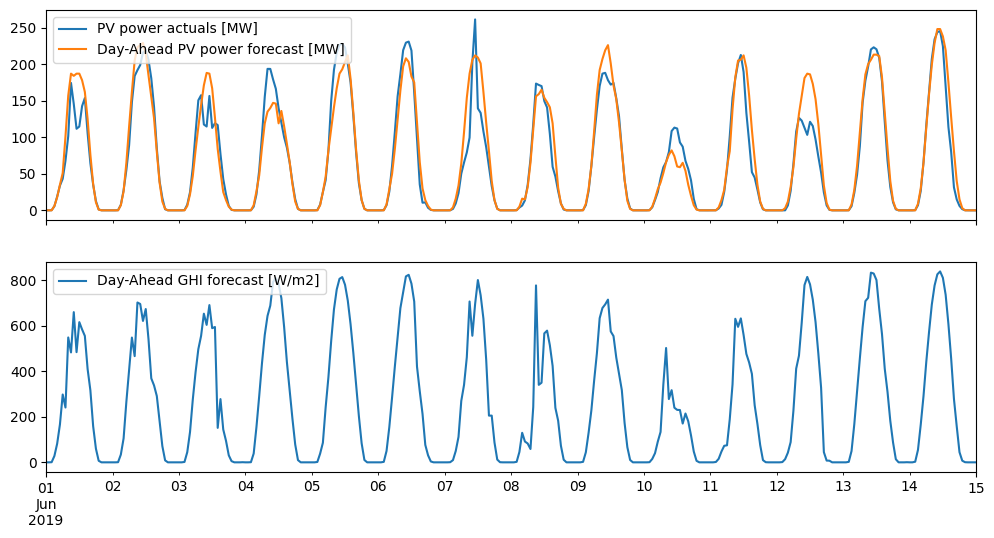

In [282]:
# Start/End dates for the plot, you can modify it for your own exploration
start = pd.to_datetime("20190601").tz_localize("UTC")
end = pd.to_datetime("20190615").tz_localize("UTC")

# Extract timeseries over the selected period.
pv_act = df.loc[start:end, "power_act_mw"]
pv_fc = df.loc[start:end, "power_fc_mw"]
ghi_fc = df.loc[start:end, "ghi_fc_w.m2"]

# Create a figure with two vertically stacked subplots.
fig, axes = plt.subplots(2 , 1, figsize=(12,6), sharex=True)

# Plot measured and forecasted PV power production on the top plot
pv_act.plot(ax=axes[0], label="PV power actuals [MW]")
pv_fc.plot(ax=axes[0], label="Day-Ahead PV power forecast [MW]")

# Plot forecasted GHI on the second subplot.
ghi_fc.plot(ax=axes[1], label="Day-Ahead GHI forecast [W/m2]")

# Add legends
axes[0].legend()
axes[1].legend()

## I. Residual analysis: first part




#### <span style="color:red"> I.a. Compute the PV power residuals for each timestamp </span>


#### Suggestions

Create a new column `residual` in 'df' and visualise it

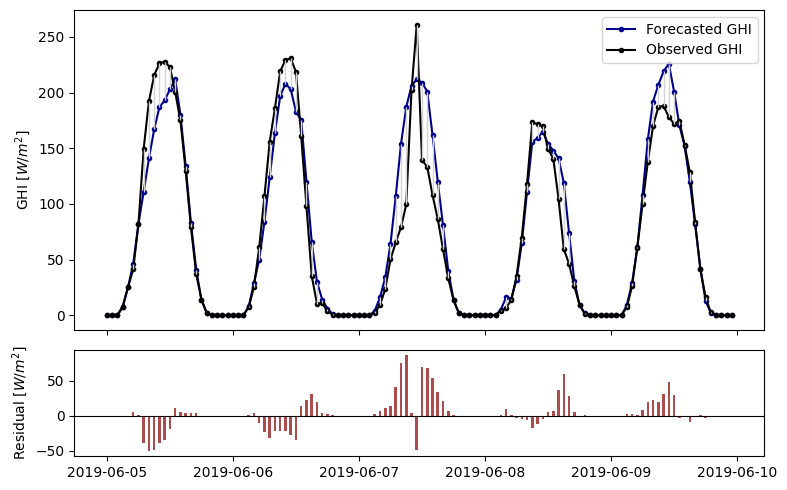

In [311]:
# Write something here on your own. 

# Compute forecast residuals.
df["residuals"] = df["power_fc_mw"] - df["power_act_mw"]

# Select a visualization period from 5 June 2019 to 9 June 2019 (included)
s = "20190605"
e = "20190609"

# Extract observed power, forecasted power, and residuals.
ghi_act = df.loc[s:e, "power_act_mw"]
ghi_fc = df.loc[s:e, "power_fc_mw"]
residual = df.loc[s:e, "residuals"]

# Create a figure with two subplots (top: raw timeseroes, bottom: residuals). 
# The top plot height =  3 times the bottom plot's height
fig, axes = plt.subplots(2, 1, figsize=(8, 5), height_ratios=[3, 1], sharex=True)

# Plot Forecast/Observed timeseries
axes[0].plot(
    ghi_fc.index,
    ghi_fc.values,
    color="darkblue",
    marker=".",
    label="Forecasted GHI",
)

axes[0].plot(
    ghi_act.index,
    ghi_act.values,
    color="black",
    marker=".",
    label="Observed GHI",
)

# Grey vertical lines between forecast and observation
axes[0].vlines(
    ghi_fc.index,
    ghi_fc.values,
    ghi_act.values,
    color="lightgrey",
    linewidth=1,
)

axes[0].set_ylabel("GHI $[W/m^2]$")
axes[0].legend()

# Residual subplot with bars
axes[1].axhline(0, color="k", linewidth=0.8)
axes[1].bar(
    residual.index,
    residual.values,
    color="darkred",
    alpha=0.7, # transparency
    width=0.02,  # bar width
)
axes[1].set_ylabel("Residual $[W/m^2]$")

plt.tight_layout()
plt.show()

#### <span style="color:red"> I.b. Calculate the Mean Bias Error (MBE) and standard deviation (STD) </span>

In [284]:
# Write something here on your own. 

# Compute the metrics
mbe = residual.mean()
std = residual.std()

# Print the metrics
print(f"MBE: {mbe:.1f}")
print(f"STD: {std:.1f}")

# Normalize the metrics by the mean observed production.
mbe_perc = mbe/df["power_act_mw"].mean() * 100
std_perc = std/df["power_act_mw"].mean() * 100
print(f"MBE [%]: {mbe_perc:.1f}")
print(f"STD [%]: {std_perc:.1f}")

MBE: 3.4
STD: 22.3
MBE [%]: 8.9
STD [%]: 57.9


#### <span style="color:red"> I.c. Generate the scatter plot and residual distribution </span>

#### Suggestions

- For the scatter plot, 'plt.scatter()' from matplotlib could be usefull, https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html
- For the residual distribution, 'sns.histplot()' with kde=True could also be usefull, https://seaborn.pydata.org/generated/seaborn.histplot.html 

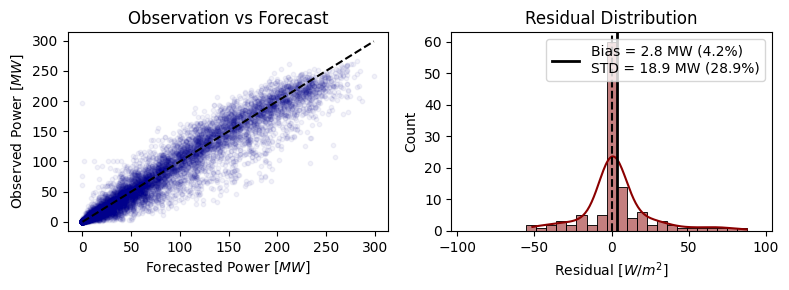

In [312]:
# Write something here on your own. 

def residual_plot(df, filter):
    # Create a filtered copy of the dataframe to keep only relevant samples.    
    df_copy = df.loc[filter].copy()

    # Metrics
    mbe = (df_copy["residuals"]).mean()
    std = (df_copy["residuals"]).std()
    mbe_perc= mbe / df_copy["power_act_mw"].mean() * 100
    std_perc= std / df_copy["power_act_mw"].mean()* 100

    # Create two subplots:
    # - Left: Forecast vs Observation scatter plot
    # - Right: Residual distribution
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    
    # Scatter plot
    axes[0].scatter(df_copy["power_fc_mw"], df_copy["power_act_mw"], alpha=0.05, color="darkblue", s=10)
    
    # 1:1 line
    lims = [min(df_copy["power_fc_mw"].min(), df_copy["power_act_mw"].min()), max(df_copy["power_fc_mw"].max(), df_copy["power_act_mw"].max())]
    axes[0].plot(lims, lims, "k--", alpha=1)
    
    axes[0].set_xlabel("Forecasted Power $[MW]$")
    axes[0].set_ylabel("Observed Power $[MW]$")
    axes[0].set_title("Observation vs Forecast")
    
    # Residual distribution on the right
    sns.histplot(
        residual.dropna(),
        kde=True,
        bins=np.linspace(-std*5, std*5, 30),
        color="darkred",
        ax=axes[1],
    )
    
    # Bias line
    axes[1].axvline(
        residual.mean(),
        color="black",
        ls="-",
        lw=2,
        label=f"Bias = {mbe:.1f} MW ({mbe_perc:.1f}%)\nSTD = {std:.1f} MW ({std_perc:.1f}%)",
    )
    axes[1].legend()
    axes[1].axvline(0, color="black", ls="--")
    axes[1].set_xlabel("Residual $[W/m^2]$")
    axes[1].set_title("Residual Distribution")
    
    plt.tight_layout()
    
    return fig, axes

# Apply the analysis only to periods with positive observed production.
filter = df["power_act_mw"] > 0
_ = residual_plot(df, filter) # "_" as outputs that I am not interested in storing

#### <span style="color:red"> I.d. Apply one of the tests to test if the residuals are gaussian, independent over time or it has constant variance </span>

#### Hints

- Shapiro-Wilk Test: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html
- Ljung–Box test: https://www.statsmodels.org/devel/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html
- Breusch-Pagan Test: https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_breuschpagan.html 

In [292]:
# Write something here on your own. 

from scipy.stats import shapiro

# Shapiro-Wilk test for normality
_, p_value = shapiro(residual)

print(f"p-value = {p_value:.3f}")

alpha = 0.05
if p_value < alpha:
    print("Reject H0: the residuals are not Gaussian.") 
else:
    print("Fail to reject H0: the residuals are consistent with a Gaussian distribution.")

p-value = 0.000
Reject H0: the residuals are not Gaussian.


In [294]:
# Perform the Ljung-Box test on the residuals.
output = acorr_ljungbox(residual)

# Extract the p-value for lag 1.
p_value = output["lb_pvalue"].loc[1]
print(f"p-value = {p_value:.3f}")

if p_value < 0.05:
    print("Reject H0: residuals exhibit autocorrelation.")
else:
    print("Fail to reject H0: residuals are independent.")

p-value = 0.000
Reject H0: residuals exhibit autocorrelation.


In [293]:
# Example: test whether residual variance depends on forecast values
X = sm.add_constant(df["power_fc_mw"])

# Breusch-Pagan test
_, lm_pvalue, _, _ = het_breuschpagan(df["residuals"], X)

print(f"p-value   = {f_pvalue:.3f}")

alpha = 0.05
if lm_pvalue < alpha:
    print("Reject H0: residuals exhibit heteroscedasticity (non-constant variance).")
else:    
    print("Fail to reject H0: residuals have approximately constant variance.")

p-value   = 0.000
Reject H0: residuals exhibit heteroscedasticity (non-constant variance).


## II. Residual analysis: second part

#### <span style="color:red"> Based on the example below, show how the residuals vary as function of the forecasted global horizontal irradiance </span>

Under what conditions are the forecasts error the largest ? 

Which error patterns do you notice ?

                           power_act_mw  power_fc_mw  ghi_fc_w.m2  residuals
2018-01-01 07:00:00+00:00          0.63          0.0     0.330537      -0.63
2018-01-01 08:00:00+00:00          4.24          5.0     9.585571       0.76
2018-01-01 09:00:00+00:00         13.09          7.0    20.493290      -6.09
2018-01-01 10:00:00+00:00         20.74         11.0    27.765103      -9.74
2018-01-01 11:00:00+00:00         18.10         11.0    44.622486      -7.10
Overcasted forecasted
Cloudy forecasted
Cleasky forecasted


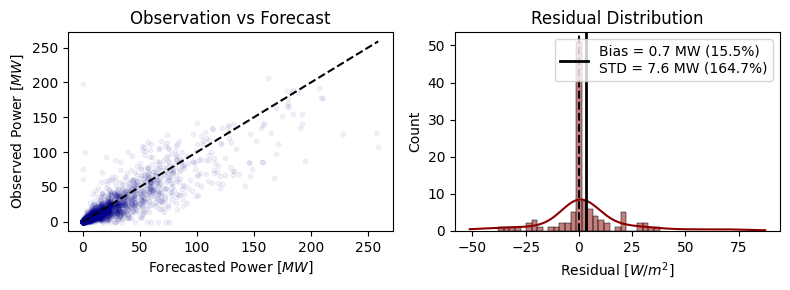

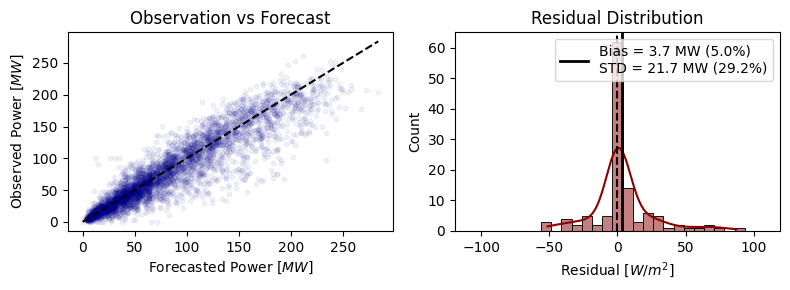

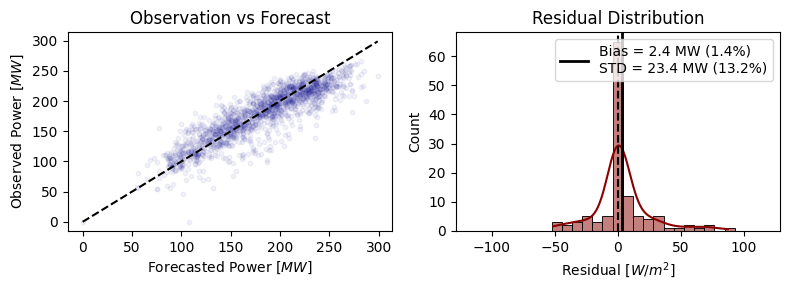

In [295]:
# An example to filter & select only the lines where forecasted GHI is under 500 W/m^2 (and still positive).
mask_500 = (df["ghi_fc_w.m2"] > 0) & (df["ghi_fc_w.m2"] < 500)
new_df = df.loc[mask_500].copy() # A new dataframe is (copied) and created

print(new_df.head())

# Continue here on your own. 

# Risø lat/lon
lat, lon = 55.68, 12.10

# Compute the solar position and extraterrestrial DNI for the middle of the intervals 
solar_position = pvlib.solarposition.get_solarposition(
    df.index + pd.Timedelta(minutes=30), lat, lon, tz="CET"
)
solar_position.index = solar_position.index -  pd.Timedelta(minutes=30)
df["dni_extra"] = pvlib.irradiance.get_extra_radiation(df.index + pd.Timedelta(minutes=30)).values

# Compute the clearness index
df["kt"] = pvlib.irradiance.clearness_index(df["ghi_fc_w.m2"], solar_position["zenith"], df["dni_extra"])

# Plot for different sky conditions
print("Overcasted forecasted")
filter = df["kt"] < 0.3
fig, ax = residual_plot(df, filter)

print("Cloudy forecasted")
filter = (df["kt"] >= 0.3) & (df["kt"] < 0.65)
fig, ax = residual_plot(df, filter)

print("Cleasky forecasted")
filter = (df["kt"] >= 0.65) 
fig, ax = residual_plot(df, filter)

## III. Probabilistic Forecasting

In the following exercises, we will move from **single-point forecasts** to **probabilistic forecasts**.

The following examples require a **training phase** where the model must be calibrated using historical observations. We will compare two approaches:

1. **Gaussian Residual Model**
2. **Gradient Boosting Quantile Regression**

We first split the dataset into training and testing periods. All model parameters will be learned using the training set only, while performance evaluation will be performed on a separate dataset: the test set.

#### III. 1. Gaussian residual model


A simple way to build a probabilistic forecast is to model the forecast errors (residuals) as a Gaussian distribution.


If the residuals are approximately Gaussian and centred around zero, we can write:

$$
e_t \sim \mathcal{N}(0,\sigma^2)
$$

where $\sigma$ is the standard deviation of the residuals.


The point forecast $\hat{y}_t$ is therefore interpreted as the mean of a probability distribution.
The spread of the distribution can then be estimated directly from historical residuals through the gaussian distribution with $ \sigma = \mathrm{std}(e_t) $

#### <span style="color:red"> - Compute the standard deviation from 2018 observations and generate the 0.10, 0.25, 0.75, and 0.90 quantiles for 2019. </span>
#### <span style="color:red"> - Also visualize the timeseries over a period of 10 days  </span>

In [301]:
# Example to generate 0.5/0.6 quantile based on a standard deviation

# Select the training dataset (2018 only)
df_train = df[df.index.year == 2018].copy()

# I advise to only train (and test) the models only during daytime (to avoid overflowing the model with too many 0s)
filter = df_train["ghi_fc_w.m2"] > 0 

# Compute the quantile offsets (deltas) from a Gaussian distribution.
# These deltas are later added to the deterministic forecast as qx = fc_deterministic + qx_delta
q_050_delta = norm.ppf(0.5, scale=df_train.loc[filter, "residuals"].std()) # 0, since it is assumed to be centered on 0
q_060_delta = norm.ppf(0.6, scale=df_train.loc[filter, "residuals"].std())

# Continue here on your own. 
df_test = df[df.index.year == 2019].copy()
filter =  df_test["ghi_fc_w.m2"] > 0

for quantile in np.arange(0.05, 1, 0.05):
    df_test[f"q_{int(quantile*100)}"] = df_test.loc[filter, "power_fc_mw"] + norm.ppf(quantile, scale=df_train["residuals"].std())

print(df_test[["power_fc_mw", "q_10",  "q_75"]].head(15))

                           power_fc_mw       q_10       q_75
2019-01-01 00:00:00+00:00          0.0        NaN        NaN
2019-01-01 01:00:00+00:00          0.0        NaN        NaN
2019-01-01 02:00:00+00:00          0.0        NaN        NaN
2019-01-01 03:00:00+00:00          0.0        NaN        NaN
2019-01-01 04:00:00+00:00          0.0        NaN        NaN
2019-01-01 05:00:00+00:00          0.0        NaN        NaN
2019-01-01 06:00:00+00:00          0.0        NaN        NaN
2019-01-01 07:00:00+00:00          0.0 -17.972459   9.459033
2019-01-01 08:00:00+00:00         10.0  -7.972459  19.459033
2019-01-01 09:00:00+00:00         28.0  10.027541  37.459033
2019-01-01 10:00:00+00:00         42.0  24.027541  51.459033
2019-01-01 11:00:00+00:00         45.0  27.027541  54.459033
2019-01-01 12:00:00+00:00         36.0  18.027541  45.459033
2019-01-01 13:00:00+00:00         20.0   2.027541  29.459033
2019-01-01 14:00:00+00:00          4.0 -13.972459  13.459033


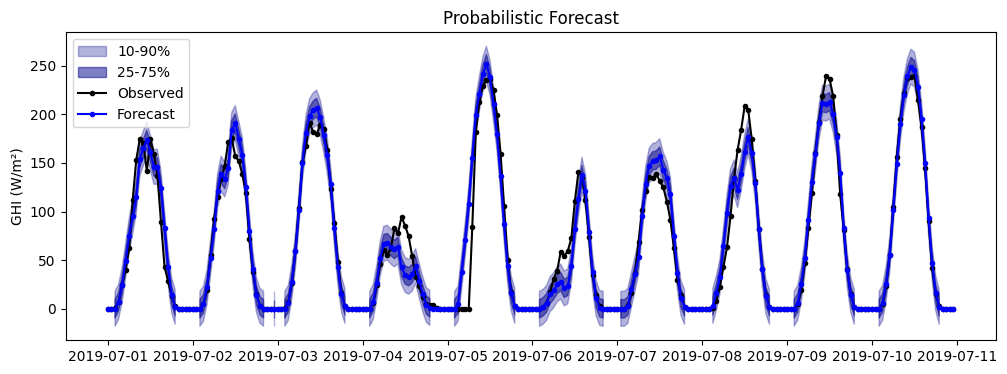

In [302]:
# Select a visualization period from 1 July 2019 to 10 July 2019
s = "2019-07-01"
e = "2019-07-10"
df_visu = df_test.loc[s:e]

def prob_visualization(df_visu):

    # Create figure and axes
    fig, ax = plt.subplots(figsize=(12,4))

    # Plot the 10%-90% prediction interval. (shaded area)
    ax.fill_between(
        df_visu.index,
        df_visu["q_10"],
        df_visu["q_90"],
        alpha=0.3, # transparency parameter
        color="darkblue",
        label="10-90%"
    )

    # Plot the 25%-75% prediction interval. (shaded area)
    ax.fill_between(
        df_visu.index,
        df_visu["q_25"],
        df_visu["q_75"],
        alpha=0.5, # transparency parameter
        color="darkblue",
        label="25-75%"
    )

    # Plot the observed power production with markers.
    ax.plot(
        df_visu.index,
        df_visu["power_act_mw"],
        label="Observed",
        color="black",
        marker=".",
    )

    # Plot the deterministic forecast.
    ax.plot(
        df_visu.index,
        df_visu["power_fc_mw"],
        label="Forecast",
        color="blue",
        marker="."
    )

    # Add title, label and legend on the figure
    ax.set_title("Probabilistic Forecast")
    ax.set_ylabel("GHI (W/m²)")
    ax.legend()
    

prob_visualization(df_visu)

#### III. 2. Machine Learning Approach: Gradient Boosting Quantile Regression

Instead of assuming that forecast errors follow a predefined probability distribution, quantile regression estimates specific quantiles of the target variable conditional on the input features.

For a quantile level $\tau \in (0,1)$, the model estimates the $\hat{q}_{\tau}(x_t)$ is the predicted $\tau$-quantile given the predictors $x_t$.

A Gradient Boosting model can be trained separately for each quantile using the pinball loss function.

Info: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html 



#### <span style="color:red"> - Train Gradient Boosting quantile regression models on the 2018 data (following the example below) and generate the 0.10, 0.25, 0.75, and 0.90 quantile forecasts for 2019.</span>
#### <span style="color:red">Compare the predicted quantiles with the point forecast and visualize the resulting prediction intervals over one representative day.</span>

In [304]:
# Example: train a model for the 10th quantile with default GradientBoosting regressor parameters

# Split the dataset into:
# - Training set: year 2018
# - Testing set: year 2019
df_train = df[df.index.year == 2018].copy()
df_test_gb = df[df.index.year == 2019].copy()

# Target quantile to estimate (10th percentile)
quantile = 0.10

# Create a Gradient Boosting model configured for quantile regression with loss="quantile" for the indicated quantile (alpha).
gb_q10 = GradientBoostingRegressor(
        loss="quantile",
        alpha=quantile,
    )

# I advise to only train (and test) the models only during daytime (to avoid overflowing the model with too many 0s)
filter = df_train["ghi_fc_w.m2"] > 0 
X_train = df_train.loc[filter, ["power_fc_mw"]] # Forecasted power (directly) as feature
y_train = df_train.loc[filter, "power_act_mw"] # Actual power as target to make quantile for
gb_q10.fit(X_train, y_train) # Train the quantile regression model on 2018 data


# Forest on 2019
filter = df_test_gb["power_fc_mw"] > 0  # Apply the same daytime filter to the test set
X_test = df_test_gb.loc[filter, ["power_fc_mw"]] # test feature
fc_output = gb_q10.predict(X_test) # Forecast the 10th quantile of actual power 
q_010 = pd.Series(fc_output, index=X_test.index) # add the correct index (and convert the object to pd.Series)

df_test_gb["q_10"] =  q_010 # Store the variable

# Continue here on your own for

# loop over the quantiles and create one model per quantile (+ forecast on 2019 with it)
for quantile in np.arange(0.05, 1, 0.05):
    gb_q = GradientBoostingRegressor(
        loss="quantile",
        alpha=quantile,
    )
    
    filter = df_train["ghi_fc_w.m2"] > 0 # I advise to only train (and test) the models only during daytime (to avoid overflowing the model with too many 0s)
    X_train = df_train.loc[filter, ["power_fc_mw"]]
    y_train = df_train.loc[filter, "power_act_mw"]
    gb_q.fit(X_train, y_train)
    
    
    filter = df_test["power_fc_mw"] > 0 
    X_test = df_test.loc[filter, ["power_fc_mw"]]
    fc_output = gb_q.predict(X_test)
    q = pd.Series(fc_output, index=X_test.index) # add the correct index
    
    df_test_gb[f"q_{int(quantile * 100)}"] =  q

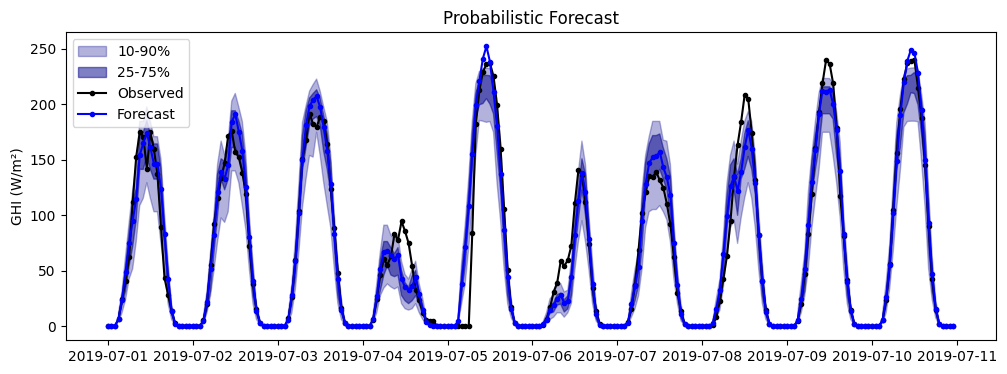

In [267]:
s = "2019-07-01"
e = "2019-07-10"
df_visu = df_test_gb.loc[s:e]

prob_visualization(df_visu)

#### III. 3. Assess probabilistic forecasts with reliability diagram



A reliability diagram evaluates whether the predicted quantiles are statistically consistent with the observations.

For a quantile level $\tau$, the empirical coverage is computed as:

$$
\hat{p}_{\tau}
=
\frac{1}{N}
\sum_{t=1}^{N}
\mathbf{1}
\left(
y_t \leq \hat{q}_{\tau,t}
\right)
$$


where:

- $y_t$ is the observed value,
- $\hat{q}_{\tau,t}$ is the predicted quantile,
- $\mathbf{1}(\cdot)$ is the indicator function.


The reliability diagram is obtained by plotting the empirical coverage $\hat{p}_{\tau}$ on the y-axis against the nominal coverage $\tau$ on the x-axis.
The closer the points are to the diagonal line, the better calibrated the probabilistic forecast.

#### <span style="color:red">  For both Gaussian-residual and Gradient Boosting approaches: </span>

#### <span style="color:red">  i.  Using the 2025 observations and quantile forecasts, compute the empirical coverage for the [0.10, 0.25, 0.50, 0.75, 0.9] (for day time) </span>

####  <span style="color:red"> ii. Create a reliability diagram and compare the empirical coverage.</span>

In [307]:
# Example to compute the reliability of a quantile (0.1)
y_test = np.array([0.1, 0.3, 0.4, 0.6]) # dummy test for illustration

tau = 0.10
q_010 = np.array([0.15, 0.05, 0.1, 0.2]) # dummy test for illustration

# Fraction of observations below the predicted quantile
coverage = np.mean(y_test <= q_010)

print(f"Nominal coverage : {tau:.2f}") # point on the x-axis
print(f"Empirical coverage: {coverage:.2f}") # point on the y-axis


# Write on your own

# Compute all reliabilities for all quantiles from 5% to 95%
quantiles = np.arange(0.05, 1, 0.05)

# Lists that will store the empirical coverages
gaussian_cov = []
gb_cov = []
for q in quantiles:
    # Compute empirical coverage for the Gaussian approach
    filter = df_test["ghi_fc_w.m2"] > 0
    coverage = np.mean(
        df_test.loc[filter, "power_act_mw"]
        <= df_test.loc[filter, f"q_{int(q*100)}"]
    )

    gaussian_cov.append(coverage) # Add it to the list

    # Compute empirical coverage for the Gradient Boosting approach
    filter = df_test_gb["ghi_fc_w.m2"] > 0
    gb_coverage = np.mean(
        df_test_gb.loc[filter, "power_act_mw"]
        <= df_test_gb.loc[filter, f"q_{int(q*100)}"]
    )

    gb_cov.append(gb_coverage) # Add it to the list

Nominal coverage : 0.10
Empirical coverage: 0.25


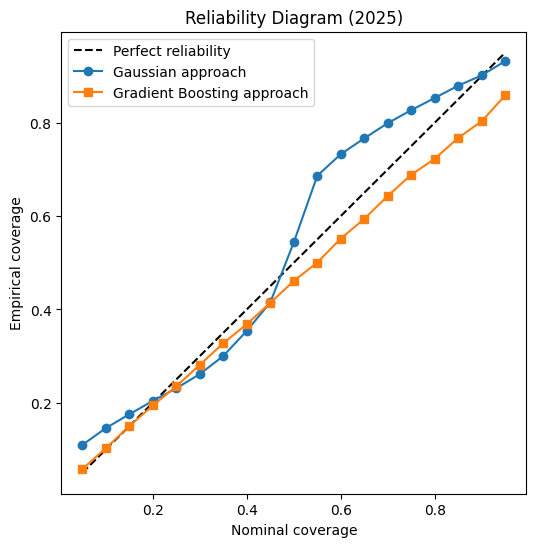

In [308]:
# Create the reliability diagram.
fig, ax = plt.subplots(figsize=(6,6))

# A perfectly calibrated probabilistic forecast would lie exactly on this diagonal.
ax.plot(
    quantiles,
    quantiles,
    "k--",
    label="Perfect reliability"
)

# Plot the empirical coverage obtained from the Gaussian quantile model.

ax.plot(
    quantiles,
    gaussian_cov,
    "o-",
    label="Gaussian approach"
)

# Plot the empirical coverage obtained from the Gradient Boosting quantile model.
ax.plot(
    quantiles,
    gb_cov,
    "s-",
    label="Gradient Boosting approach"
)

# Add labels and legends
ax.set_xlabel("Nominal coverage")
ax.set_ylabel("Empirical coverage")
ax.set_title("Reliability Diagram (2025)")
ax.legend()


# It seems that the Gradient Boosting approach is slightly closer in average to the diagonal, and then a better model. 
# The slight negative bias could be due to the increase in PV capacity in Denmark from 2018 to 2019